# Student Academic Data — Exploratory Data Analysis

This notebook explores five CSV files: attendance, homework/assignments, exam performance, student information, and teacher-parent communications.

**Before running:** Place all five CSV files in the same folder as this notebook. Run cells from top to bottom.

This is exploratory analysis only; it does not yet create an academic-risk target or train a predictive model. Student names and emergency-contact details are not used as analytical features.

In [1]:
# 1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 80)

DATA_DIR = Path(".")
FILES = {
    "communications": "teacher_parent_communication.csv",
    "students": "students.csv",
    "performance": "performance.csv",
    "homework": "homework.csv",
    "attendance": "attendance.csv",
}
print("Ready. Expected CSV folder:", DATA_DIR.resolve())

Ready. Expected CSV folder: /mnt/data


In [2]:
# 2. Load all five datasets
data = {name: pd.read_csv(DATA_DIR / filename) for name, filename in FILES.items()}
for name, df in data.items():
    print(f"{name}: {len(df):,} rows × {len(df.columns)} columns")

communications: 24,312 rows × 4 columns
students: 12,156 rows × 5 columns
performance: 36,468 rows × 5 columns
homework: 60,780 rows × 7 columns
attendance: 364,680 rows × 4 columns


In [3]:
# 3. Dataset overview: dimensions, missing cells, duplicates, unique students
overview = pd.DataFrame([
    {
        "Dataset": name,
        "Rows": len(df),
        "Columns": len(df.columns),
        "Missing cells": int(df.isna().sum().sum()),
        "Exact duplicate rows": int(df.duplicated().sum()),
        "Unique students": int(df["Student_ID"].nunique())
    }
    for name, df in data.items()
])
display(overview)

for name, df in data.items():
    print(f"\\n{name.upper()} — data types and missing values")
    display(pd.DataFrame({
        "Data type": df.dtypes.astype(str),
        "Missing values": df.isna().sum(),
        "Unique values": df.nunique(dropna=False)
    }))

,Dataset,Rows,Columns,Missing cells,Exact duplicate rows,Unique students
0,communications,24312,4,0,0,10512
1,students,12156,5,618,0,12156
2,performance,36468,5,0,0,11580
3,homework,60780,7,0,0,12065
4,attendance,364680,4,0,290,12156


\nCOMMUNICATIONS — data types and missing values


,Data type,Missing values,Unique values
Student_ID,object,0,10512
Date,object,0,183
Message_Type,object,0,3
Message_Content,object,0,23086


\nSTUDENTS — data types and missing values


,Data type,Missing values,Unique values
Student_ID,object,0,12156
Full_Name,object,0,11442
Date_of_Birth,object,0,5350
Grade_Level,object,0,5
Emergency_Contact,object,618,11539


\nPERFORMANCE — data types and missing values


,Data type,Missing values,Unique values
Student_ID,object,0,11580
Subject,object,0,6
Exam_Score,int64,0,71
Homework_Completion_%,object,0,5
Teacher_Comments,object,0,32918


\nHOMEWORK — data types and missing values


,Data type,Missing values,Unique values
Student_ID,object,0,12065
Subject,object,0,6
Assignment_Name,object,0,56065
Due_Date,object,0,366
Status,object,0,6
Grade_Feedback,object,0,8
Guardian_Signature,object,0,3


\nATTENDANCE — data types and missing values


,Data type,Missing values,Unique values
Student_ID,object,0,12156
Date,object,0,366
Subject,object,0,6
Attendance_Status,object,0,8


In [4]:
# 4. Review categorical values with low cardinality
for name, df in data.items():
    print(f"\\n--- {name.upper()} ---")
    for col in df.select_dtypes(include="object").columns:
        if df[col].nunique(dropna=False) <= 30:
            print(f"\\n{col}")
            display(df[col].value_counts(dropna=False).rename_axis("Value").reset_index(name="Count"))

\n--- COMMUNICATIONS ---


\nMessage_Type


,Value,Count
0,Teacher to Parent,8149
1,Automated Reminder,8106
2,Parent to Teacher,8057


\n--- STUDENTS ---
\nGrade_Level


,Value,Count
0,Grade 5,2472
1,Grade 4,2454
2,Grade 3,2447
3,Grade 2,2400
4,Grade 1,2383


\n--- PERFORMANCE ---
\nSubject


... (12 outputs left out)

\nSubject


,Value,Count
0,Math,61241
1,Science,60881
2,Arabic,60749
3,English,60684
4,Geography,60640
5,History,60485


\nAttendance_Status


,Value,Count
0,PRESENT,45982
1,Absent,45751
2,Present,45632
3,Late,45509
4,late,45508
5,absnt,45478
6,left early,45435
7,excused,45385


In [5]:
# 5. Check attendance duplicates and repeated student-date-subject keys
attendance = data["attendance"].copy()
print("Exact duplicate attendance rows:", int(attendance.duplicated().sum()))
print("Repeated Student_ID + Date + Subject keys:",
      int(attendance.duplicated(["Student_ID", "Date", "Subject"]).sum()))
display(attendance[
    attendance.duplicated(["Student_ID", "Date", "Subject"], keep=False)
].sort_values(["Student_ID", "Date", "Subject"]).head(10))

Exact duplicate attendance rows: 290


Repeated Student_ID + Date + Subject keys: 2380


,Student_ID,Date,Subject,Attendance_Status
245552,S00004,2024-12-24,Geography,absnt
302174,S00004,2024-12-24,Geography,Late
21914,S00007,2024-10-14,English,excused
190486,S00007,2024-10-14,English,absnt
285963,S00007,2025-03-04,Arabic,Present
324124,S00007,2025-03-04,Arabic,PRESENT
156976,S00019,2024-09-23,History,excused
251658,S00019,2024-09-23,History,excused
53814,S00021,2024-10-25,English,PRESENT
144824,S00021,2024-10-25,English,excused


In [6]:
# 6. Parse dates that use mixed formats
students = data["students"].copy()
homework = data["homework"].copy()
communications = data["communications"].copy()
attendance = data["attendance"].copy()

students["DOB_parsed"] = pd.to_datetime(students["Date_of_Birth"], format="mixed", errors="coerce")
homework["Due_Date_parsed"] = pd.to_datetime(homework["Due_Date"], format="mixed", errors="coerce")
communications["Date_parsed"] = pd.to_datetime(communications["Date"], format="mixed", errors="coerce")
attendance["Date_parsed"] = pd.to_datetime(attendance["Date"], format="mixed", errors="coerce")

date_quality = pd.DataFrame([
    ["students", "Date_of_Birth", students["DOB_parsed"].isna().sum(), students["DOB_parsed"].min(), students["DOB_parsed"].max()],
    ["homework", "Due_Date", homework["Due_Date_parsed"].isna().sum(), homework["Due_Date_parsed"].min(), homework["Due_Date_parsed"].max()],
    ["communications", "Date", communications["Date_parsed"].isna().sum(), communications["Date_parsed"].min(), communications["Date_parsed"].max()],
    ["attendance", "Date", attendance["Date_parsed"].isna().sum(), attendance["Date_parsed"].min(), attendance["Date_parsed"].max()],
], columns=["Dataset", "Date column", "Unparseable dates", "Earliest", "Latest"])
display(date_quality)

,Dataset,Date column,Unparseable dates,Earliest,Latest
0,students,Date_of_Birth,0,2006-03-11,2019-03-09
1,homework,Due_Date,0,2024-09-08,2025-03-09
2,communications,Date,0,2024-09-08,2025-03-09
3,attendance,Date,0,2024-03-09,2025-03-09


,Attendance status,Records
0,present,91614
1,absent,91229
2,late,91017
3,left early,45435
4,excused,45385


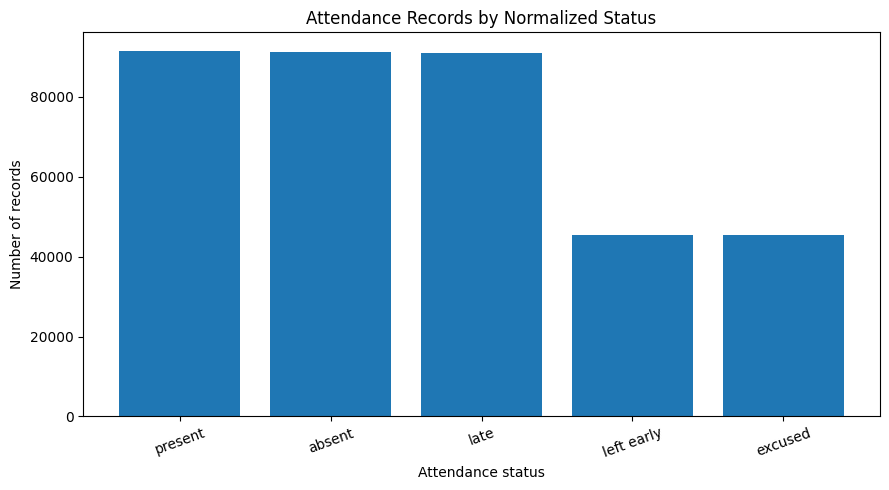

In [7]:
# 7. Attendance status distribution after label normalization
# This creates a separate analysis column; original values are preserved.
attendance["Status_clean"] = attendance["Attendance_Status"].astype(str).str.strip().str.lower()
attendance["Status_clean"] = attendance["Status_clean"].replace({"absnt": "absent"})
attendance_counts = attendance["Status_clean"].value_counts()

display(attendance_counts.rename_axis("Attendance status").reset_index(name="Records"))

plt.figure(figsize=(9, 5))
plt.bar(attendance_counts.index.astype(str), attendance_counts.values)
plt.title("Attendance Records by Normalized Status")
plt.xlabel("Attendance status")
plt.ylabel("Number of records")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

,Homework status,Records
0,done,30381
1,not done,20385
2,pending,10014


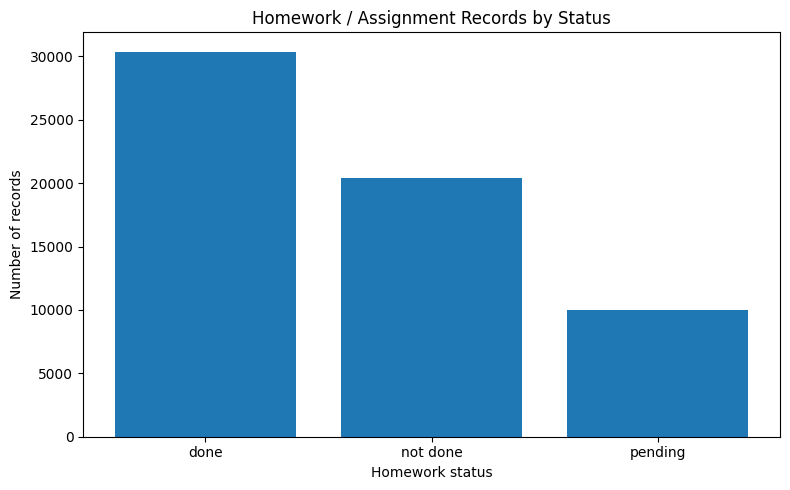

In [8]:
# 8. Homework / assignment status distribution after normalization
homework["Status_clean"] = homework["Status"].astype(str).str.strip().str.lower()
homework["Status_clean"] = homework["Status_clean"].replace({
    "✔": "done", "✅": "done", "❌": "not done"
})
homework_counts = homework["Status_clean"].value_counts()

display(homework_counts.rename_axis("Homework status").reset_index(name="Records"))

plt.figure(figsize=(8, 5))
plt.bar(homework_counts.index.astype(str), homework_counts.values)
plt.title("Homework / Assignment Records by Status")
plt.xlabel("Homework status")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

,Exam score
count,36468.000000
mean,74.964243
std,20.538704
min,40.000000
25%,57.000000
50%,75.000000
75%,93.000000
max,110.000000


Scores below 0: 0
Scores above 100: 5139


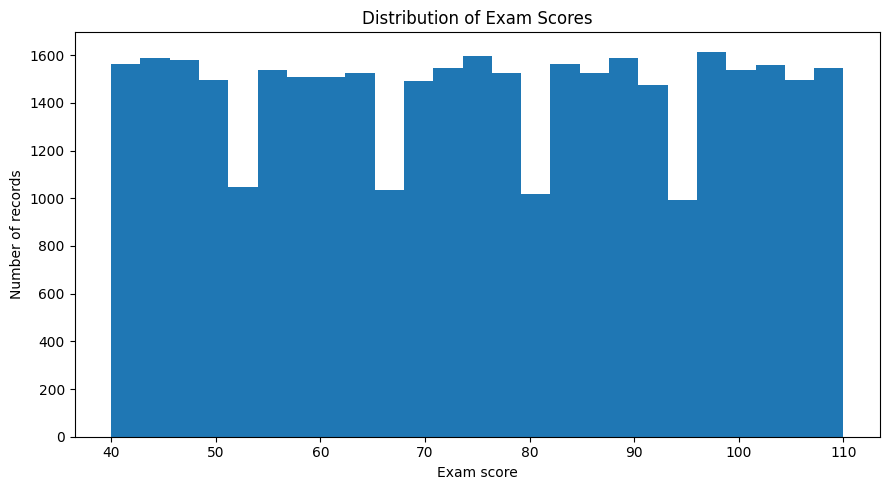

In [9]:
# 9. Exam score descriptive statistics and distribution
performance = data["performance"].copy()
performance["Exam_Score"] = pd.to_numeric(performance["Exam_Score"], errors="coerce")
display(performance["Exam_Score"].describe().to_frame("Exam score"))

print("Scores below 0:", int((performance["Exam_Score"] < 0).sum()))
print("Scores above 100:", int((performance["Exam_Score"] > 100).sum()))

plt.figure(figsize=(9, 5))
plt.hist(performance["Exam_Score"].dropna(), bins=25)
plt.title("Distribution of Exam Scores")
plt.xlabel("Exam score")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

,Homework completion value
count,36468.000000
mean,71.810766
std,39.238666
min,-5.000000
25%,80.000000
50%,90.000000
75%,95.000000
max,100.000000


Values outside 0–100: 7376


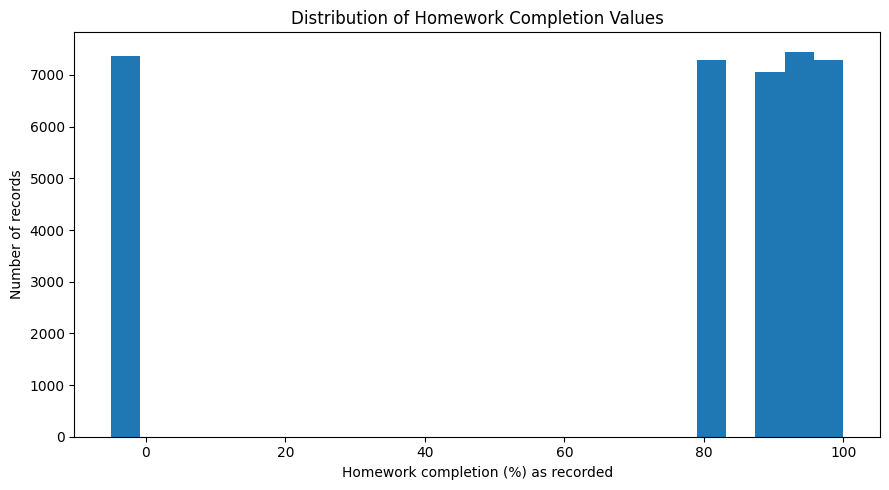

In [10]:
# 10. Homework completion values: convert text and percentage signs to numeric
performance["Homework_Completion_numeric"] = pd.to_numeric(
    performance["Homework_Completion_%"].astype(str).str.replace("%", "", regex=False),
    errors="coerce"
)
display(performance["Homework_Completion_numeric"].describe().to_frame("Homework completion value"))

outside_range = (
    (performance["Homework_Completion_numeric"] < 0) |
    (performance["Homework_Completion_numeric"] > 100)
)
print("Values outside 0–100:", int(outside_range.sum()))

plt.figure(figsize=(9, 5))
plt.hist(performance["Homework_Completion_numeric"].dropna(), bins=25)
plt.title("Distribution of Homework Completion Values")
plt.xlabel("Homework completion (%) as recorded")
plt.ylabel("Number of records")
plt.tight_layout()
plt.show()

,Grade level,Students
0,Grade 1,2383
1,Grade 2,2400
2,Grade 3,2447
3,Grade 4,2454
4,Grade 5,2472


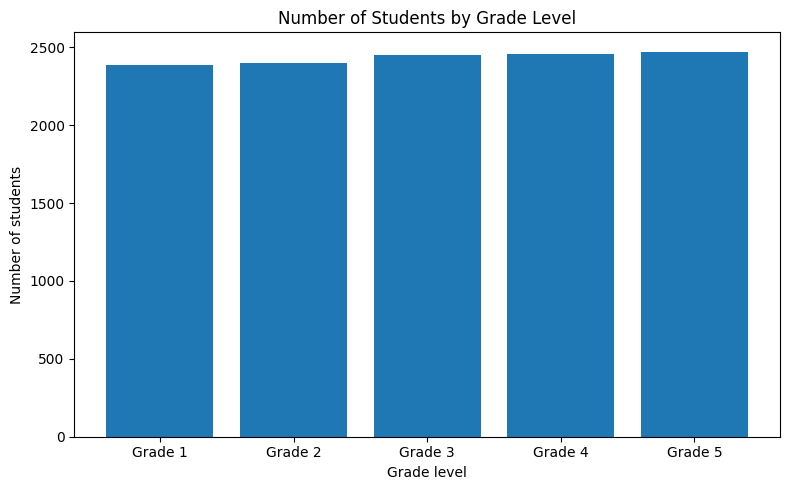

In [11]:
# 11. Student counts by grade level
grade_order = ["Grade 1", "Grade 2", "Grade 3", "Grade 4", "Grade 5"]
grade_counts = students["Grade_Level"].value_counts().reindex(grade_order)
display(grade_counts.rename_axis("Grade level").reset_index(name="Students"))

plt.figure(figsize=(8, 5))
plt.bar(grade_counts.index.astype(str), grade_counts.values)
plt.title("Number of Students by Grade Level")
plt.xlabel("Grade level")
plt.ylabel("Number of students")
plt.tight_layout()
plt.show()

Matched student-subject performance records: 36226
Pearson correlation: -0.00432990196799593


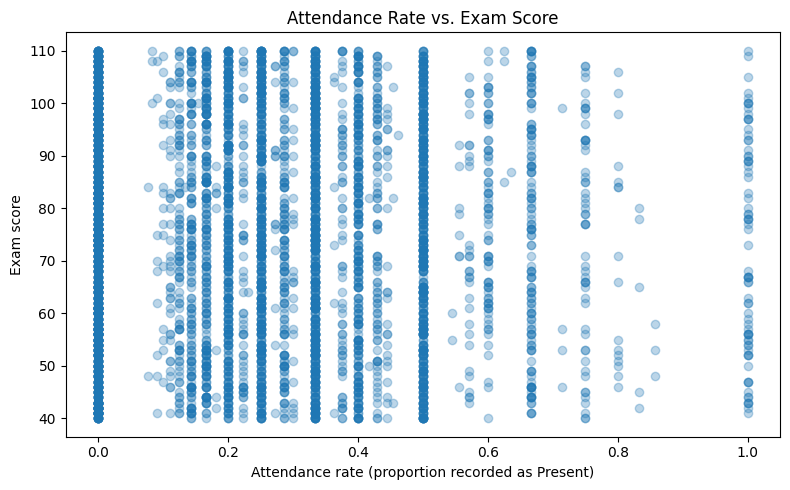

In [12]:
# 12. Explore attendance rate and exam score at student-subject level
attendance["is_present"] = (attendance["Status_clean"] == "present").astype(int)
attendance_summary = (
    attendance.groupby(["Student_ID", "Subject"], as_index=False)
    .agg(attendance_rate=("is_present", "mean"),
         attendance_records=("is_present", "size"))
)

performance_attendance = performance.merge(
    attendance_summary, on=["Student_ID", "Subject"], how="inner"
)
print("Matched student-subject performance records:", len(performance_attendance))
print("Pearson correlation:", performance_attendance[["Exam_Score", "attendance_rate"]].corr().iloc[0, 1])

plot_data = performance_attendance.sample(
    min(5000, len(performance_attendance)), random_state=42
)
plt.figure(figsize=(8, 5))
plt.scatter(plot_data["attendance_rate"], plot_data["Exam_Score"], alpha=0.3)
plt.title("Attendance Rate vs. Exam Score")
plt.xlabel("Attendance rate (proportion recorded as Present)")
plt.ylabel("Exam score")
plt.tight_layout()
plt.show()

## Interpretation notes and cautions

- Attendance and homework status labels require standardization before aggregation or modeling.
- The attendance table contains duplicate records and repeated student-date-subject keys. Investigate these before deciding which rows to retain.
- Homework completion includes values outside the 0–100 range. Verify their meaning before correcting or removing them.
- Exam scores above 100 require confirmation of the grading scale.
- The student table contains personal information. Do not use names or emergency contacts as predictive features; protect these details in the paper and notebook.
- Plots show distributions and associations, not causation.
- Do not define an At-Risk target from model results. Use an official grading rule or an instructor-approved definition.

,Risk Status,Number of Records
0,Not At-Risk,18502
1,At-Risk,17966


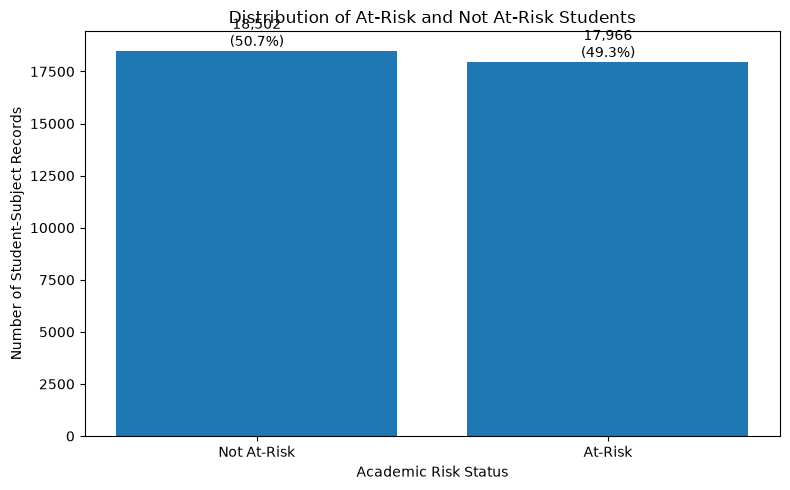

In [14]:
# 13. At-Risk vs. Not At-Risk Distribution
# Set this using your institution's official passing-score requirement.
PASS_THRESHOLD = 75  # CHANGE THIS if the official threshold is different

performance["Risk_Status"] = np.where(
    performance["Exam_Score"] < PASS_THRESHOLD,
    "At-Risk",
    "Not At-Risk"
)

risk_counts = performance["Risk_Status"].value_counts()

display(
    risk_counts.rename_axis("Risk Status")
    .reset_index(name="Number of Records")
)

plt.figure(figsize=(8, 5))

plt.bar(
    risk_counts.index,
    risk_counts.values
)

plt.title("Distribution of At-Risk and Not At-Risk Students")
plt.xlabel("Academic Risk Status")
plt.ylabel("Number of Student-Subject Records")

for i, count in enumerate(risk_counts.values):
    percentage = count / risk_counts.sum() * 100
    plt.text(i, count, f"{count:,}\n({percentage:.1f}%)",
             ha="center", va="bottom")

plt.tight_layout()
plt.show()

## use GAM or Elastic Net Logistic Regression